In [73]:
import matplotlib.pyplot as plt
from analysis.io import load_dataset
import numpy as np
from analysis.enem_codes import INCOME_MIDPOINTS
import pandas as pd

In [74]:
d = load_dataset("enem")
X, y, names = d["X_train"], d["y_train"], d["feature_names"]

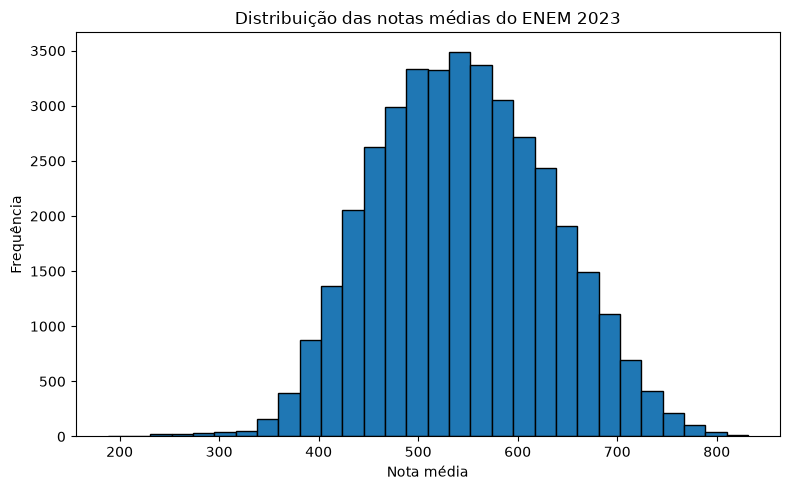

In [75]:
plt.figure(figsize=(8, 5))
plt.hist(y, bins=30, edgecolor="black")
plt.xlabel("Nota média")
plt.ylabel("Frequência")
plt.title("Distribuição das notas médias do ENEM 2023")
plt.tight_layout()
plt.show()

In [76]:
indice = np.where(names == "school_3")[0][0]
school = X[:, indice]

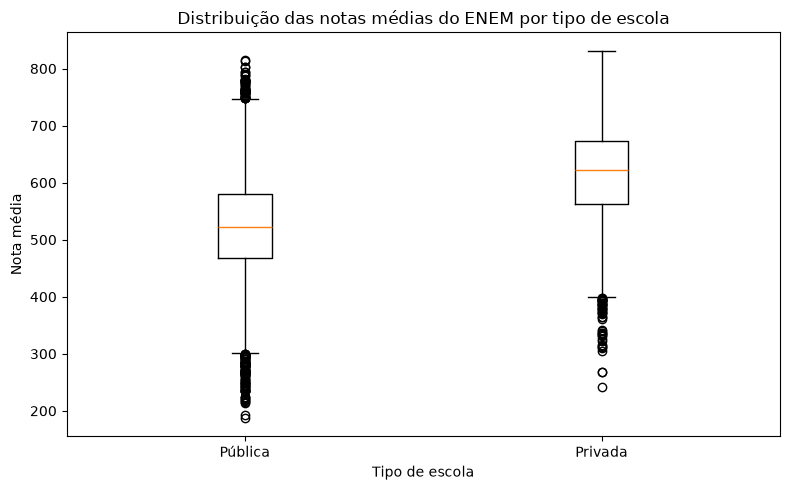

In [77]:
grades_by_school = [
    y[school == 0],
    y[school == 1]
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    grades_by_school,
    tick_labels=["Pública", "Privada"]
)
plt.xlabel("Tipo de escola")
plt.ylabel("Nota média")
plt.title("Distribuição das notas médias do ENEM por tipo de escola")
plt.tight_layout()
plt.show()

In [78]:
education_idx = np.where(names == "mother_education")[0][0]
unknown_education_idx = np.where(names == "mother_education_unknown")[0][0]
household_size_idx = np.where(names == "household_size")[0][0]
income_idx = np.where(names == "log_income_per_capita")[0][0]

education = X[:, education_idx].copy()
unknown_education = X[:, unknown_education_idx]
household_size = X[:, household_size_idx]
log_income_pc = X[:, income_idx]

household_income = household_size * np.expm1(log_income_pc)

print("Primeiras rendas reconstruídas:", household_income[:10])
print("Primeiras escolaridades:", education[:10])

Primeiras rendas reconstruídas: [4620. 2310. 2970. 4620.  660. 1650. 2310. 1650. 2310.    0.]
Primeiras escolaridades: [5. 4. 5. 1. 2. 3. 2. 4. 5. 0.]


In [ ]:
income_midpoints = np.array(list(INCOME_MIDPOINTS.values()), dtype=float)
    
distances = np.abs(household_income[:, None] - income_midpoints[None, :])
category_indices = np.argmin(distances, axis=1)

income_midpoint = income_midpoints[category_indices] 

print("Maior diferença na reconstrução:",
      np.max(np.min(distances, axis=1)))

Maior diferença na reconstrução: 2.1827872842550278e-11


In [80]:
education_labels = {
    0: "Nunca estudou",
    1: "Não completou 4ª/5º ano",
    2: "Completou 4ª/5º ano, mas não 8ª/9º ano",
    3: "Completou 8ª/9º ano, mas não Ensino Médio",
    4: "Completou Ensino Médio, mas não faculdade",
    5: "Completou faculdade, mas não pós-graduação",
    6: "Completou pós-graduação",
}

known_education_mask = unknown_education == 0

education_rotulo = np.array([
    education_labels[int(value)]
    for value in education[known_education_mask]
])